In [19]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from collections import Counter

# Dataset paths
TRAIN_PATH = "/kaggle/input/datasets/suyashnpande/devanagarihandwrittencharacterdataset/DevanagariHandwrittenCharacterDataset/Train"
TEST_PATH  = "/kaggle/input/datasets/suyashnpande/devanagarihandwrittencharacterdataset/DevanagariHandwrittenCharacterDataset/Test"

In [20]:
import os

print("=== TRAIN CLASSES (first 10) ===")
train_classes = sorted(os.listdir(TRAIN_PATH))
for c in train_classes[:10]:
    n = len(os.listdir(os.path.join(TRAIN_PATH, c)))
    print(f"  {c}: {n} images")

print(f"\nTotal train classes: {len(train_classes)}")

print("\n=== TEST CLASSES (first 10) ===")
test_classes = sorted(os.listdir(TEST_PATH))
for c in test_classes[:10]:
    n = len(os.listdir(os.path.join(TEST_PATH, c)))
    print(f"  {c}: {n} images")

print(f"\nTotal test classes: {len(test_classes)}")

=== TRAIN CLASSES (first 10) ===
  character_10_yna: 1700 images
  character_11_taamatar: 1700 images
  character_12_thaa: 1700 images
  character_13_daa: 1700 images
  character_14_dhaa: 1700 images
  character_15_adna: 1700 images
  character_16_tabala: 1700 images
  character_17_tha: 1700 images
  character_18_da: 1700 images
  character_19_dha: 1700 images

Total train classes: 46

=== TEST CLASSES (first 10) ===
  character_10_yna: 300 images
  character_11_taamatar: 300 images
  character_12_thaa: 300 images
  character_13_daa: 300 images
  character_14_dhaa: 300 images
  character_15_adna: 300 images
  character_16_tabala: 300 images
  character_17_tha: 300 images
  character_18_da: 300 images
  character_19_dha: 300 images

Total test classes: 46


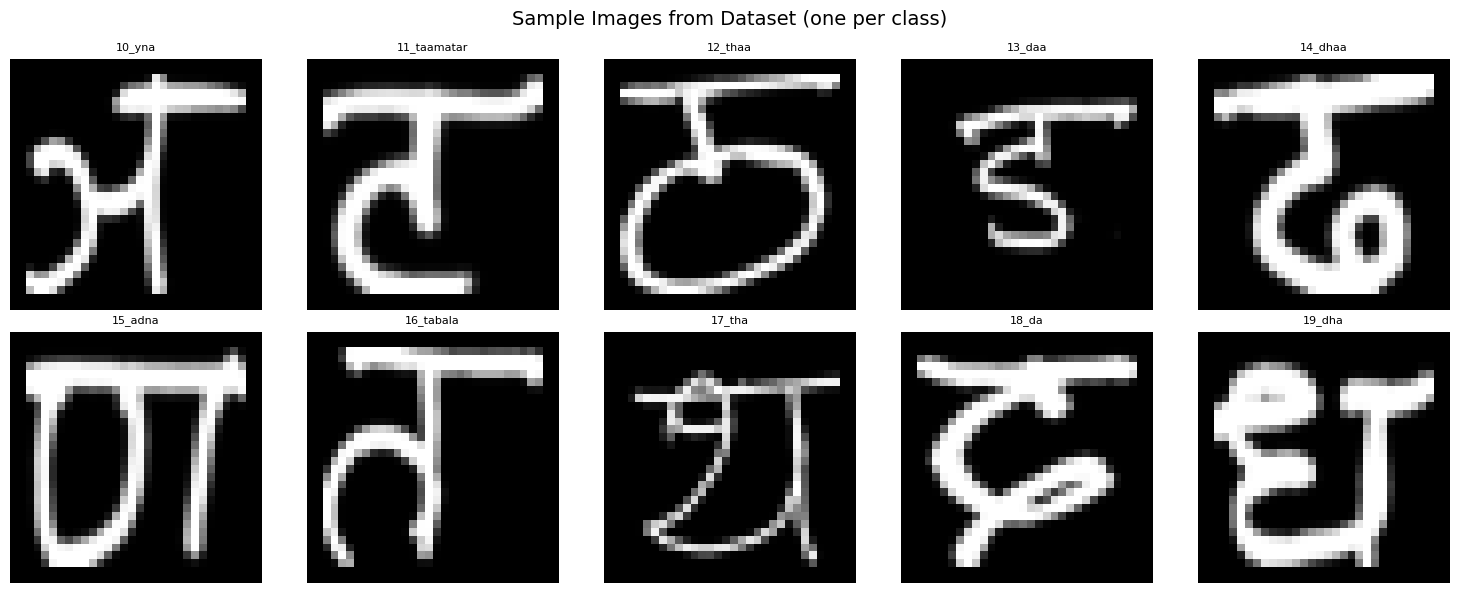

In [21]:
import matplotlib.image as mpimg

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Sample Images from Dataset (one per class)", fontsize=14)

sample_classes = train_classes[:10]
for ax, cls in zip(axes.flatten(), sample_classes):
    cls_path = os.path.join(TRAIN_PATH, cls)
    img_file = os.listdir(cls_path)[0]
    img = mpimg.imread(os.path.join(cls_path, img_file))
    ax.imshow(img, cmap="gray")
    ax.set_title(cls.replace("character_", "").replace("digit_", "d_"), fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
])

train_full = datasets.ImageFolder(TRAIN_PATH, transform=transform)
test       = datasets.ImageFolder(TEST_PATH,  transform=transform)

# 80% train, 20% validation split
train_size = int(0.8 * len(train_full))
val_size   = len(train_full) - train_size

train, val = random_split(train_full, [train_size, val_size],
                           generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train, batch_size=64, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val,   batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test,  batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

# idx_to_class must come from train_full (not the subset)
idx_to_class = {v: k for k, v in train_full.class_to_idx.items()}

print(f"Train samples      : {len(train)}")
print(f"Validation samples : {len(val)}")
print(f"Test samples       : {len(test)}  ← kept unexposed")
print(f"Num classes        : {len(train_full.classes)}")

Train samples      : 62560
Validation samples : 15640
Test samples       : 13800  ← kept unexposed
Num classes        : 46


In [23]:
for X, y in train_loader:
    print(f"Train batch — images: {X.size()}, labels: {y.size()}")
    break

for X, y in test_loader:
    print(f"Test  batch — images: {X.size()}, labels: {y.size()}")
    break

Train batch — images: torch.Size([64, 1, 32, 32]), labels: torch.Size([64])
Test  batch — images: torch.Size([64, 1, 32, 32]), labels: torch.Size([64])


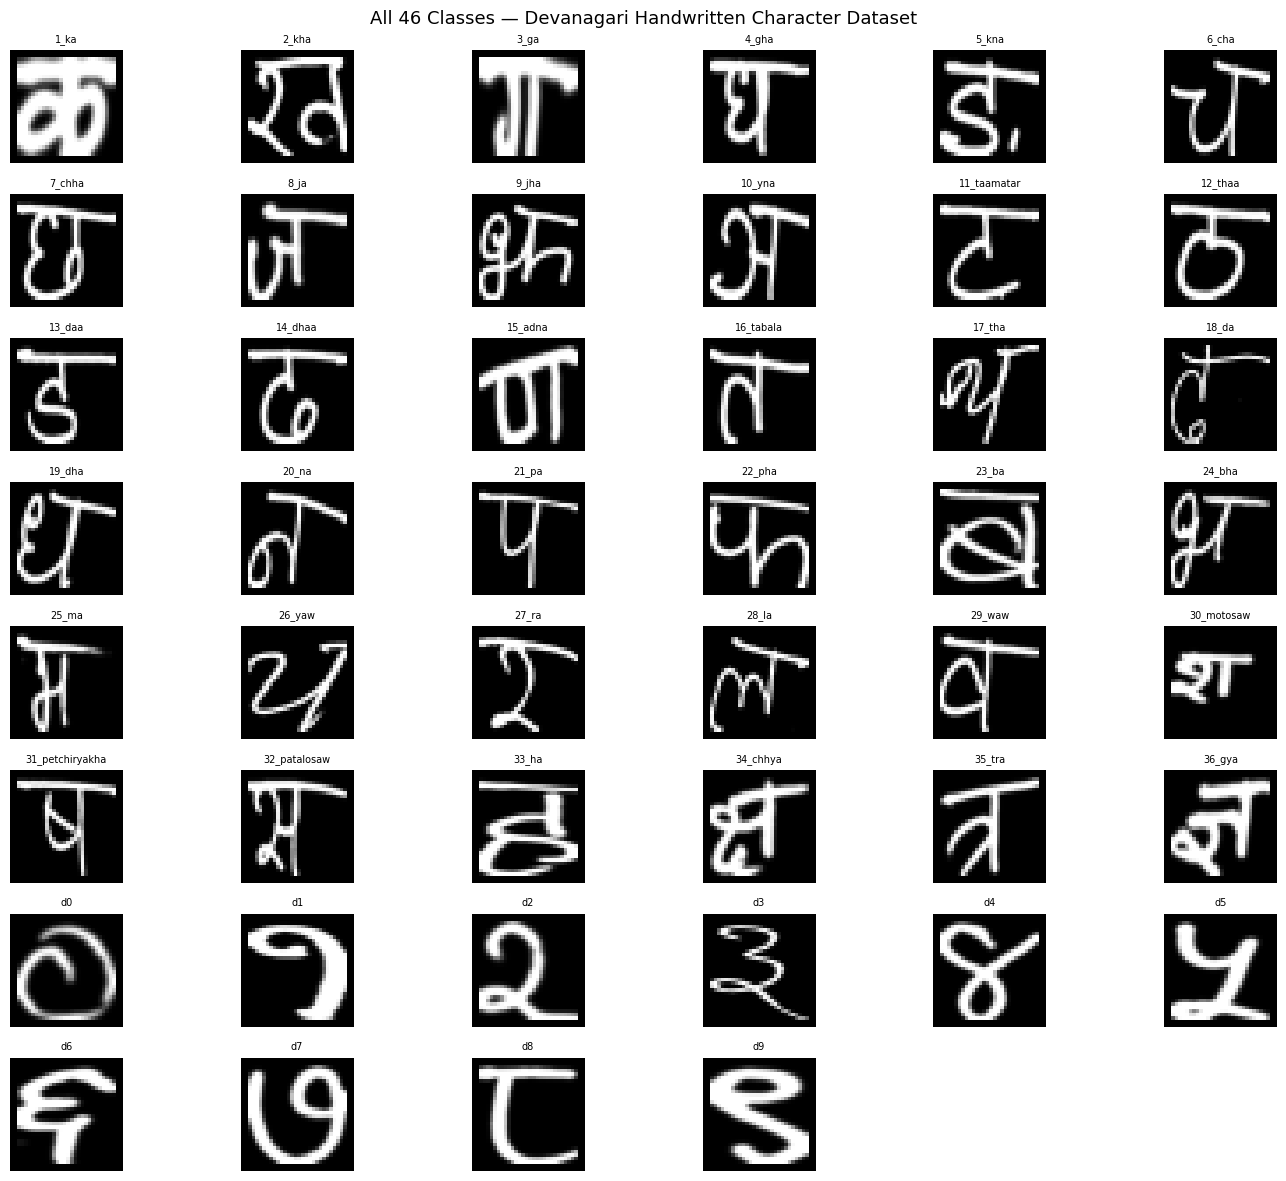

In [25]:
varnamala_order = [
    "character_1_ka", "character_2_kha", "character_3_ga", "character_4_gha", "character_5_kna",
    "character_6_cha", "character_7_chha", "character_8_ja", "character_9_jha", "character_10_yna",
    "character_11_taamatar", "character_12_thaa", "character_13_daa", "character_14_dhaa", "character_15_adna",
    "character_16_tabala", "character_17_tha", "character_18_da", "character_19_dha", "character_20_na",
    "character_21_pa", "character_22_pha", "character_23_ba", "character_24_bha", "character_25_ma",
    "character_26_yaw", "character_27_ra", "character_28_la", "character_29_waw",
    "character_30_motosaw", "character_31_petchiryakha", "character_32_patalosaw", "character_33_ha",
    "character_34_chhya", "character_35_tra", "character_36_gya",
    "digit_0", "digit_1", "digit_2", "digit_3", "digit_4",
    "digit_5", "digit_6", "digit_7", "digit_8", "digit_9"
]


# collect one sample per class — iterate train_full not train
samples = {}
for img, label in train_full:        # ← train_full here
    cname = idx_to_class[label]
    if cname not in samples:
        samples[cname] = img
    if len(samples) == len(train_full.classes):   # ← train_full here
        break

cols = 6
rows = (len(varnamala_order) + cols - 1) // cols

plt.figure(figsize=(14, 12))
for i, cname in enumerate(varnamala_order):
    img = samples[cname].squeeze(0)
    plt.subplot(rows, cols, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(cname.replace("character_", "").replace("digit_", "d"), fontsize=7)
    plt.axis("off")

plt.suptitle("All 46 Classes — Devanagari Handwritten Character Dataset", fontsize=13)
plt.tight_layout()
plt.show()

In [27]:
label_counts = Counter(train_full.targets)


print(f"{'Class':<35} {'Count':>6}")
print("-" * 43)
for label_idx, count in sorted(label_counts.items()):
    print(f"{idx_to_class[label_idx]:<35} {count:>6}")

Class                                Count
-------------------------------------------
character_10_yna                      1700
character_11_taamatar                 1700
character_12_thaa                     1700
character_13_daa                      1700
character_14_dhaa                     1700
character_15_adna                     1700
character_16_tabala                   1700
character_17_tha                      1700
character_18_da                       1700
character_19_dha                      1700
character_1_ka                        1700
character_20_na                       1700
character_21_pa                       1700
character_22_pha                      1700
character_23_ba                       1700
character_24_bha                      1700
character_25_ma                       1700
character_26_yaw                      1700
character_27_ra                       1700
character_28_la                       1700
character_29_waw                      1700
character_

In [28]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [29]:
class ModelA(nn.Module):
    def __init__(self, num_classes=46):
        super(ModelA, self).__init__()

        self.conv1 = nn.Conv2d(1, 64, kernel_size=5, stride=1)
        self.lrn1  = nn.LocalResponseNorm(5, alpha=0.001, beta=0.75, k=1.0)
        self.pool1 = nn.MaxPool2d(2, stride=2)

        self.conv2 = nn.Conv2d(64, 128, kernel_size=5, stride=1)
        self.lrn2  = nn.LocalResponseNorm(5, alpha=0.001, beta=0.75, k=1.0)
        self.pool2 = nn.MaxPool2d(2, stride=2)

        self.conv3 = nn.Conv2d(128, 256, kernel_size=5, stride=1)
        self.lrn3  = nn.LocalResponseNorm(5, alpha=0.001, beta=0.75, k=1.0)

        self.dropout = nn.Dropout(0.5)
        self.fc      = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.lrn1(self.conv1(x))))
        x = self.pool2(F.relu(self.lrn2(self.conv2(x))))
        x = F.relu(self.lrn3(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        return self.fc(x)

# sanity-check output shape
dummy = torch.zeros(1, 1, 32, 32)
m = ModelA()
print("Output shape:", m(dummy).shape)   # expect torch.Size([1, 46])

Output shape: torch.Size([1, 46])


In [30]:
def get_inverse_lr_scheduler(optimizer, gamma=0.0001, power=0.75):
    def lr_lambda(iteration):
        return (1 + gamma * iteration) ** (-power)
    return optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def evaluate(model, loader, device):
    model.eval()
    total, correct = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
    return correct / total

In [31]:
def train_model(model, train_loader, val_loader, epochs=20, lr=0.005, device="cpu"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    scheduler = get_inverse_lr_scheduler(optimizer)

    iteration       = 0
    train_losses    = []
    val_accuracies  = []   # ← renamed from test_accuracies

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            scheduler.step()
            iteration    += 1
            running_loss += loss.item()

        val_acc = evaluate(model, val_loader, device=device)   # ← val not test
        train_losses.append(running_loss)
        val_accuracies.append(val_acc)

        print(f"Epoch {epoch+1:>2}/{epochs} | Loss: {running_loss:.4f} | Val Acc: {val_acc:.4f}")

    return model, train_losses, val_accuracies

In [32]:
model = ModelA(num_classes=46)
trained_model, train_losses, val_accuracies = train_model(
    model, train_loader, val_loader,      # ← val_loader here
    epochs=20, lr=0.005, device=device
)

Epoch  1/20 | Loss: 1577.4221 | Val Acc: 0.8682
Epoch  2/20 | Loss: 480.2280 | Val Acc: 0.9258
Epoch  3/20 | Loss: 314.4980 | Val Acc: 0.9457
Epoch  4/20 | Loss: 236.9695 | Val Acc: 0.9589
Epoch  5/20 | Loss: 187.8887 | Val Acc: 0.9658
Epoch  6/20 | Loss: 158.7597 | Val Acc: 0.9671
Epoch  7/20 | Loss: 135.4655 | Val Acc: 0.9714
Epoch  8/20 | Loss: 113.2009 | Val Acc: 0.9721
Epoch  9/20 | Loss: 102.2665 | Val Acc: 0.9754
Epoch 10/20 | Loss: 89.0165 | Val Acc: 0.9770
Epoch 11/20 | Loss: 80.7991 | Val Acc: 0.9772
Epoch 12/20 | Loss: 74.5311 | Val Acc: 0.9786
Epoch 13/20 | Loss: 67.5088 | Val Acc: 0.9792
Epoch 14/20 | Loss: 58.4532 | Val Acc: 0.9793
Epoch 15/20 | Loss: 56.0152 | Val Acc: 0.9806
Epoch 16/20 | Loss: 50.2441 | Val Acc: 0.9795
Epoch 17/20 | Loss: 46.7338 | Val Acc: 0.9795
Epoch 18/20 | Loss: 43.9560 | Val Acc: 0.9804
Epoch 19/20 | Loss: 39.7643 | Val Acc: 0.9811
Epoch 20/20 | Loss: 36.4283 | Val Acc: 0.9810


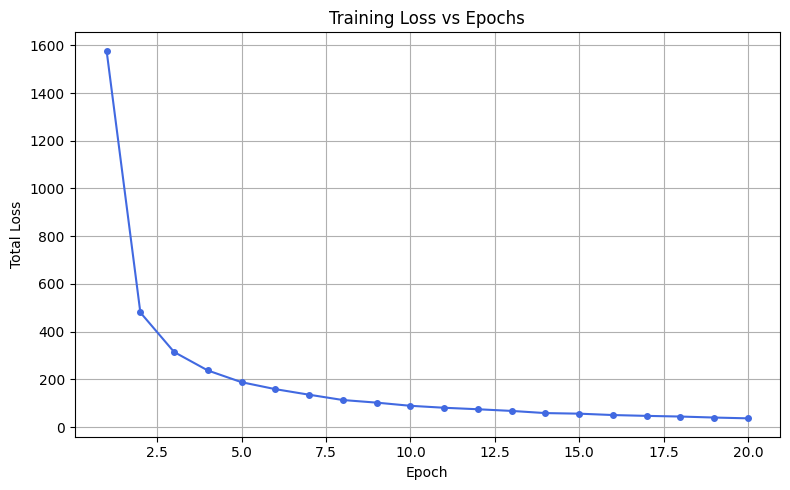

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses)+1), train_losses, color="royalblue", marker="o", markersize=4)
plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("Training Loss vs Epochs")
plt.grid(True)
plt.tight_layout()
plt.show()

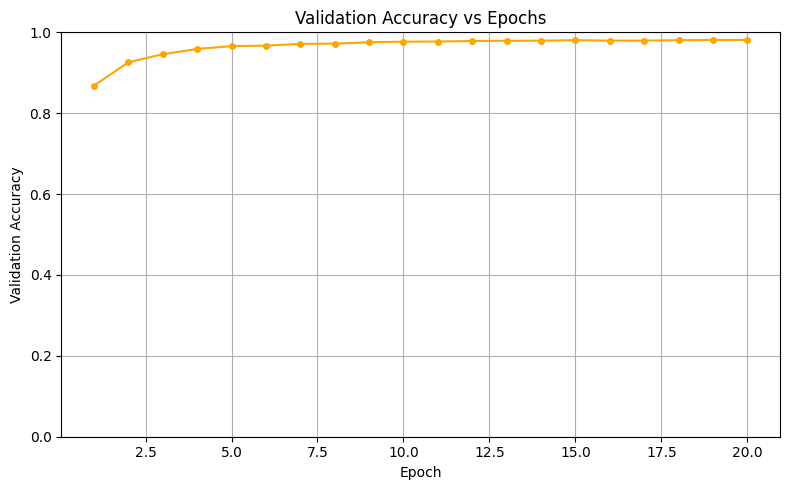

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(val_accuracies)+1), val_accuracies, color="orange", marker="o", markersize=4)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy vs Epochs")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
model = trained_model

train_acc = evaluate(model, train_loader, device=device)
val_acc   = evaluate(model, val_loader,   device=device)
test_acc  = evaluate(model, test_loader,  device=device)  # ← only revealed NOW at the end

print(f"Train Accuracy      : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Validation Accuracy : {val_acc:.4f}  ({val_acc*100:.2f}%)")
print(f"Test Accuracy       : {test_acc:.4f}  ({test_acc*100:.2f}%)  ← final score")

Train Accuracy      : 0.9991 (99.91%)
Validation Accuracy : 0.9810  (98.10%)
Test Accuracy       : 0.9818  (98.18%)  ← final score


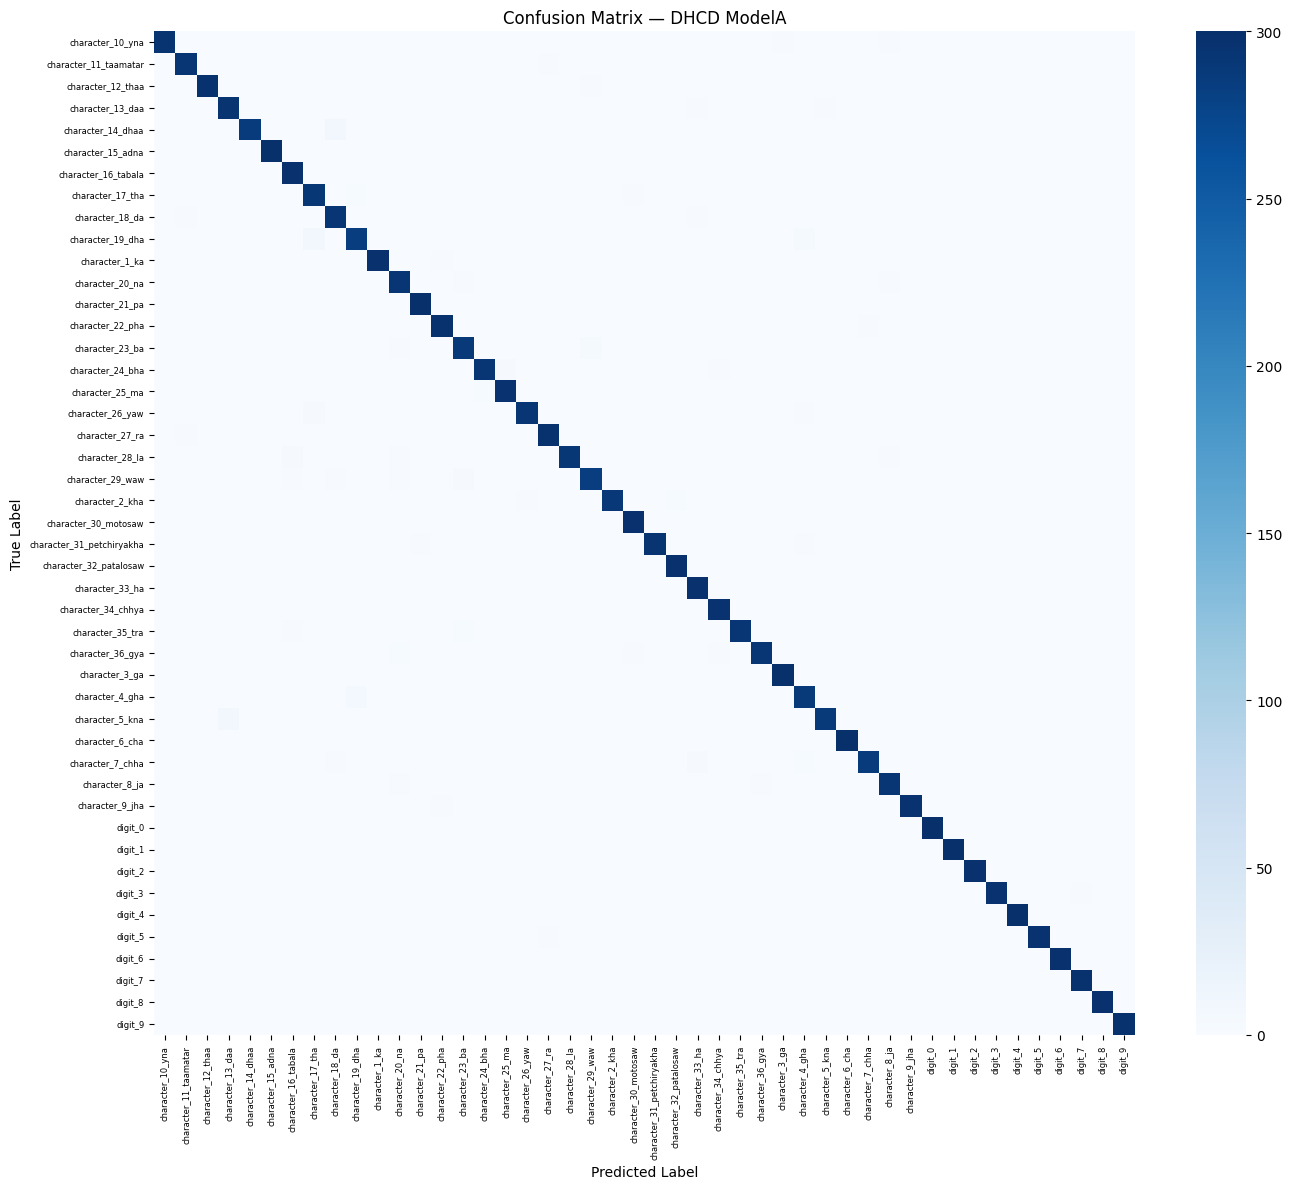

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def get_all_preds(model, loader, device):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, pred = outputs.max(1)
            preds.extend(pred.cpu().numpy())
            trues.extend(labels.cpu().numpy())
    return np.array(trues), np.array(preds)

y_true, y_pred = get_all_preds(model, test_loader, device)

cm = confusion_matrix(y_true, y_pred)
class_names = [idx_to_class[i] for i in range(len(train_full.classes))]

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.title("Confusion Matrix — DHCD ModelA")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0,  fontsize=6)
plt.tight_layout()
plt.show()

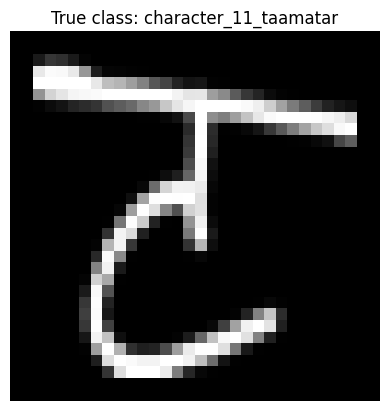

True label : character_11_taamatar
Predicted  : character_11_taamatar


In [39]:
idx = 300
img, label = test[idx]

plt.imshow(img.squeeze(), cmap="gray")
plt.title(f"True class: {idx_to_class[label]}")
plt.axis("off")
plt.show()

model.eval()
with torch.no_grad():
    output = model(img.unsqueeze(0).to(device))
    _, pred = output.max(1)

print(f"True label : {idx_to_class[label]}")
print(f"Predicted  : {idx_to_class[pred.item()]}")

In [40]:
# Save the full model in PyTorch .pt format
model = trained_model  # trained_model returned from train_model()

MODEL_SAVE_PATH = "/kaggle/working/dhcd_modelA.pt"

# Save the entire model (architecture + weights) — PyTorch .pt format
torch.save(model, MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

# Verify by checking fc bias (should not be all zeros if trained)
print("FC bias (first 5):", model.fc.bias[:5])


Model saved!
FC bias (first 5): tensor([ 0.0555, -0.0081, -0.0195, -0.0803,  0.0696], device='cuda:0',
       grad_fn=<SliceBackward0>)


In [41]:
# To reload the full model later:
# MODEL_SAVE_PATH = "/kaggle/working/dhcd_modelA.pt"
# model = torch.load(MODEL_SAVE_PATH)
# model.to(device)
# model.eval()
#
# NOTE: If you only want to save/load weights (state_dict), use:
# torch.save(model.state_dict(), "/kaggle/working/dhcd_modelA_weights.pt")
# model = ModelA(num_classes=46)
# model.load_state_dict(torch.load("/kaggle/working/dhcd_modelA_weights.pt"))
# model.to(device)
